# WEEK 6 - Feature Engineering

## Scaling, Encoding and Skewness Correction

In this week, the cleaned dataset is transformed into a form suitable
for advanced analysis.

The main steps include:

- Identifying numerical and categorical features
- Correcting skewed numerical features
- Scaling numerical variables
- Encoding categorical variables
- Preparing the transformed dataset for feature selection and PCA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Dataset/social_media_vs_productivity_modified_clean.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (30000, 19)


In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


## Feature Type Identification

Before applying transformations, the dataset features are separated into
numerical, categorical and boolean variables.

This helps us choose the correct preprocessing technique for each feature type.

In [5]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()
boolean_columns = df.select_dtypes(include=["bool"]).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nBoolean Columns:")
print(boolean_columns)

Numerical Columns:
['age', 'daily_social_media_time', 'number_of_notifications', 'work_hours_per_day', 'perceived_productivity_score', 'actual_productivity_score', 'stress_level', 'sleep_hours', 'screen_time_before_sleep', 'breaks_during_work', 'coffee_consumption_per_day', 'days_feeling_burnout_per_month', 'weekly_offline_hours', 'job_satisfaction_score']

Categorical Columns:
['gender', 'job_type', 'social_platform_preference']

Boolean Columns:
['uses_focus_apps', 'has_digital_wellbeing_enabled']


C:\Users\mdota\AppData\Local\Temp\ipykernel_13472\430897483.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()


## Skewness Analysis

Skewness is checked to identify numerical variables whose distributions
are highly asymmetric.

Features with high positive skewness may require transformation before
scaling and advanced analysis.

In [6]:
skewness_report = df[numerical_columns].skew().sort_values(ascending=False)

skewness_report

daily_social_media_time           1.262586
coffee_consumption_per_day        0.674751
stress_level                      0.124100
screen_time_before_sleep          0.123106
days_feeling_burnout_per_month    0.109118
weekly_offline_hours              0.037900
age                               0.015305
number_of_notifications           0.006991
breaks_during_work                0.006698
work_hours_per_day               -0.038162
sleep_hours                      -0.052983
actual_productivity_score        -0.105786
job_satisfaction_score           -0.153189
perceived_productivity_score     -0.350977
dtype: float64

In [7]:
highly_skewed = skewness_report[abs(skewness_report) > 1]

print("Highly Skewed Features:")
print(highly_skewed)

Highly Skewed Features:
daily_social_media_time    1.262586
dtype: float64


## Skewness Correction

Highly positively skewed numerical features are transformed using
log transformation.

The transformation reduces the influence of very large values and
makes the distribution more suitable for further analysis.

In [8]:
transformed_df = df.copy()

print("Transformation copy created successfully!")

Transformation copy created successfully!


In [9]:
for column in highly_skewed.index:
    
    # Apply only if values are non-negative
    if transformed_df[column].min() >= 0:
        transformed_df[column] = np.log1p(transformed_df[column])
        print(column, "-> Log transformation applied")

daily_social_media_time -> Log transformation applied


In [10]:
skewness_comparison = pd.DataFrame({
    "Before Transformation": df[highly_skewed.index].skew(),
    "After Transformation": transformed_df[highly_skewed.index].skew()
})

skewness_comparison

,Before Transformation,After Transformation
daily_social_media_time,1.262586,-0.788973


### Before vs After - Daily Social Media Time

The distribution before and after log transformation is visualized
to verify whether skewness has been reduced.

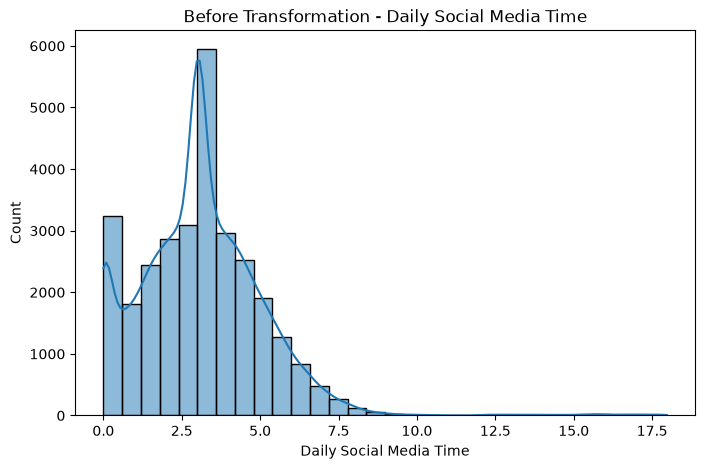

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["daily_social_media_time"],
    bins=30,
    kde=True
)

plt.title("Before Transformation - Daily Social Media Time")
plt.xlabel("Daily Social Media Time")

plt.show()

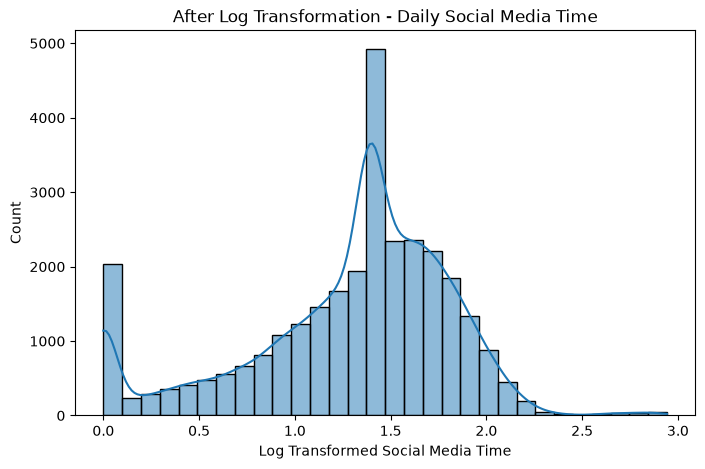

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(
    transformed_df["daily_social_media_time"],
    bins=30,
    kde=True
)

plt.title("After Log Transformation - Daily Social Media Time")
plt.xlabel("Log Transformed Social Media Time")

plt.show()

### Observation

Before transformation, daily social media time showed a strong
positive skew with a long right tail.

After applying log transformation, the distribution became more balanced
and the effect of extreme high values was reduced.

This makes the feature more suitable for scaling and further analysis.

## Feature Scaling

Feature scaling is used to bring numerical features to a comparable scale.

This is important because different features may have very different
ranges, which can influence algorithms such as PCA and distance-based methods.

Two scaling techniques are compared:

- Min-Max Scaling
- Standard Scaling

In [13]:
scaling_columns = transformed_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Columns selected for scaling:")
print(scaling_columns)

Columns selected for scaling:
['age', 'daily_social_media_time', 'number_of_notifications', 'work_hours_per_day', 'perceived_productivity_score', 'actual_productivity_score', 'stress_level', 'sleep_hours', 'screen_time_before_sleep', 'breaks_during_work', 'coffee_consumption_per_day', 'days_feeling_burnout_per_month', 'weekly_offline_hours', 'job_satisfaction_score']


### Min-Max Scaling

Min-Max Scaling transforms numerical values into a fixed range,
usually between 0 and 1.

Formula:

x' = (x - xmin) / (xmax - xmin)

In [14]:
minmax_scaler = MinMaxScaler()

minmax_df = transformed_df.copy()

minmax_df[scaling_columns] = minmax_scaler.fit_transform(
    transformed_df[scaling_columns]
)

print("Min-Max Scaling completed successfully!")

Min-Max Scaling completed successfully!


In [15]:
minmax_df[scaling_columns].describe().loc[["min", "max"]]

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### Standard Scaling

Standard Scaling transforms numerical features so that they have
approximately:

- Mean = 0
- Standard Deviation = 1

Formula:

z = (x - mean) / standard deviation

In [16]:
standard_scaler = StandardScaler()

standard_df = transformed_df.copy()

standard_df[scaling_columns] = standard_scaler.fit_transform(
    transformed_df[scaling_columns]
)

print("Standard Scaling completed successfully!")

Standard Scaling completed successfully!


In [17]:
standard_df[scaling_columns].agg(["mean", "std"]).round(2)

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
mean,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [18]:
comparison = pd.DataFrame({
    "Original": transformed_df["actual_productivity_score"].head(),
    "MinMax": minmax_df["actual_productivity_score"].head(),
    "StandardScaler": standard_df["actual_productivity_score"].head()
})

comparison

,Original,MinMax,StandardScaler
0,5.955527,0.592202,-1.679120e-01
1,6.594242,0.659083,2.042605e-01
2,8.712290,0.880868,1.438426e+00
3,4.487424,0.438474,-1.023361e+00
4,6.243694,0.622376,-1.565019e-12


## Scaling Technique Selection

Both Min-Max Scaling and Standard Scaling were tested.

For further dimensionality reduction and PCA, StandardScaler is selected
because PCA is sensitive to differences in feature magnitude.

StandardScaler ensures that numerical features contribute on a more
comparable scale by transforming them to approximately mean 0 and
standard deviation 1.

## Encoding Categorical and Boolean Features

Machine learning and dimensionality reduction techniques require numerical
input.

Therefore:

- Boolean features are converted into 0 and 1.
- Categorical features are converted using One-Hot Encoding.

In [19]:
encoded_df = standard_df.copy()

boolean_columns = [
    "uses_focus_apps",
    "has_digital_wellbeing_enabled"
]

for column in boolean_columns:
    encoded_df[column] = encoded_df[column].astype(int)

print("Boolean features encoded successfully!")

Boolean features encoded successfully!


In [20]:
categorical_columns = [
    "gender",
    "job_type",
    "social_platform_preference"
]

for column in categorical_columns:
    print(column, ":", encoded_df[column].unique())

gender : <ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
job_type : <ArrowStringArray>
['Unemployed', 'Health', 'Finance', 'IT', 'Education', 'Student']
Length: 6, dtype: str
social_platform_preference : <ArrowStringArray>
['Facebook', 'Twitter', 'Telegram', 'TikTok', 'Instagram']
Length: 5, dtype: str


In [21]:
encoded_df = pd.get_dummies(
    encoded_df,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

print("One-Hot Encoding completed successfully!")
print("New dataset shape:", encoded_df.shape)

One-Hot Encoding completed successfully!
New dataset shape: (30000, 30)


### Why One-Hot Encoding?

One-Hot Encoding is used because categorical variables such as gender,
job type and social media platform do not have a natural numerical order.

Assigning values such as Facebook = 1, Instagram = 2 and TikTok = 3 could
incorrectly imply that one platform is greater than another.

One-Hot Encoding avoids this problem by creating separate binary columns
for each category.

In [22]:
encoded_df.head()

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,...,job_type_Finance,job_type_Health,job_type_IT,job_type_Student,job_type_Unemployed,social_platform_preference_Facebook,social_platform_preference_Instagram,social_platform_preference_Telegram,social_platform_preference_TikTok,social_platform_preference_Twitter
0,1.049017,0.664385,0.796498,-0.118753,-0.978969,-1.679120e-01,1.754758,-0.867500,-0.175103,0.947731,...,0,0,0,0,1,1,0,0,0,0
1,0.326212,0.301061,-0.567176,1.090505,0.869478,2.042605e-01,-0.866457,-0.863691,0.176568,0.632640,...,0,1,0,0,0,0,0,0,0,1
2,-0.685715,0.201917,0.555850,0.460609,0.228205,1.438426e+00,-0.429588,0.239797,-1.065504,-1.572998,...,1,0,0,0,0,0,0,0,0,1
3,1.338138,0.201917,0.636066,-0.318248,0.011399,-1.023361e+00,0.007281,0.484082,-0.569603,-1.257907,...,0,0,0,0,1,1,0,0,0,0
4,-1.191679,0.201917,-1.449554,-0.388795,-1.143170,-1.565019e-12,-1.303326,0.548721,-0.199323,-1.257907,...,0,0,1,0,0,0,0,1,0,0


In [23]:
print("Final number of rows:", encoded_df.shape[0])
print("Final number of columns:", encoded_df.shape[1])
print("Missing values:", encoded_df.isnull().sum().sum())

Final number of rows: 30000
Final number of columns: 30
Missing values: 0


In [24]:
encoded_df.to_csv(
    "Dataset/feature_engineered_data.csv",
    index=False
)

print("Feature engineered dataset saved successfully!")

Feature engineered dataset saved successfully!


## Week 6 Summary

- Numerical, categorical and boolean features were identified.
- Skewness was analysed for numerical attributes.
- Log transformation was applied to highly positively skewed features.
- Min-Max Scaling and Standard Scaling were compared.
- StandardScaler was selected for further PCA analysis.
- Boolean features were converted into binary values.
- Categorical features were transformed using One-Hot Encoding.
- The final feature-engineered dataset was saved for Week 7 analysis.